# 1. A lunar lander with a fuel tank: adding a budget to a task you already train

A lander controller is in use. It was trained on Gymnasium's LunarLanderContinuous, which rewards a soft landing
on the pad, punishes a crash, and charges the fuel the engines burn. Now the lander gets a tank of 24 units, and a
lander that empties it before touching down has failed. The tank is smaller than the controller needs.

This notebook builds the problem and trains it in the open, so that you can do the same with your own task. It goes
through the steps of the [practitioner guide](../docs/practitioner-guide.md):

1. define the problem as a budget: the resource, the budget, the requirement, the price, the wrapper;
2. check the wrapped environment and plan before training;
3. train, starting from the controller in use;
4. add regularizers that use the controller as a reference;
5. compare the configurations of the full campaign, validate the policy to deploy, and report.

Short notes marked **Theory** say what the results behind the method imply at each step. The training here is short,
so that the notebook runs in a few minutes; the comparisons use the full campaign in `campaigns/` (3 million frames
per run, three seeds), which ran exactly the code shown here. It needs Gymnasium with Box2D and Stable-Baselines3.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv

from barrierpg import BudgetSpec, Requirement, Stage, BudgetWrapper, evaluate, interpret, plan
from barrierpg.callbacks import BudgetMonitor, ParameterAnchor, ActionAnchor
from barrierpg.spec import failure_tail

sys.path.insert(0, str(Path("..").resolve() / "campaigns"))
from records import Campaign                     # the records of the full campaign
camp = Campaign("lander")
torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. Define the problem as a budget

### The resource

Write a function that says how much of the resource one step consumes. It receives what the environment returns and
returns one nonnegative number per budget. The lander's task already defines its fuel use: 0.30 per unit of
main-engine power and 0.03 per unit of side-engine power.

In [2]:
def fuel_burned(obs, action, next_obs, reward, info):
    """Fuel burned in one frame, by the task's own engine-power rule."""
    main, side = float(action[0]), float(action[1])
    main_power = (min(max(main, 0.0), 1.0) + 1.0) / 2.0 if main > 0.0 else 0.0
    side_power = min(max(abs(side), 0.5), 1.0) if abs(side) > 0.5 else 0.0
    return [0.30 * main_power + 0.03 * side_power]

### The budget and the requirement

`BudgetSpec` describes the budget problem; `Requirement` states what the deployed policy must satisfy.

* `budgets`: the tank, 24 units.
* `horizon`: an episode lasts at most 1000 frames. The price is charged from a failure to the end of the horizon.
* `beta`: the discount of the task's reward. With a horizon of 1000 frames, a discount close to one keeps a late
  failure from looking cheap.
* `ubar`, `u_minus`: bounds on the reward per frame (the landing bonus and the crash penalty, 100 each). Only the
  certificates use them.
* The requirement: run dry in at most 5% of landings within the 1000 frames, shown at 95% confidence, with the
  validation error shared among the ten candidates we will inspect.

**Theory.** A loose `ubar` makes the certificates weaker but never wrong. The tolerance `alpha` and the validation
error `zeta` are different quantities: the first is about the policy, the second about the test.

In [3]:
spec = BudgetSpec(budgets=[24.0], beta=0.999, ubar=100.0, u_minus=100.0, horizon=1000)
req = Requirement(T=spec.horizon - 1, alpha=0.05, zeta=0.05, family=10)

### The price

A `Stage` sets how a failure is charged. `Stage(m=0.5)` charges a price of 0.5 per frame from the failure to the end
of the episode. The task's own reward punishes a crash with -100, below any price we would use, so we set
`clip_utility=False`: only the failure is priced, and the task's rewards are left as they are.

**Theory.** With a fixed price, a policy that is optimal for the priced objective is the best policy among all those
that fail no more often than it does; a higher price chooses a safer point on the trade-off between reward and risk.
The wrapper's reward is clipped at `-m` from below, which would erase a crash penalty below `-m`; the results need
`m >= u_minus` when clipping is on, hence `clip_utility=False` here.

In [4]:
stage = Stage(m=0.5, clip_utility=False)
for t in (0, 500, 900):
    print(f"a failure at frame {t} is charged {failure_tail(stage.m, spec.beta, t, spec.horizon):6.1f}")

a failure at frame 0 is charged  316.2
a failure at frame 500 is charged  196.8
a failure at frame 900 is charged   47.6


### The wrapper

`BudgetWrapper` puts these together around the task. It adds the remaining fuel, as a fraction of the tank, to the
observation; the policy needs it. It ends the episode when the tank runs dry and charges the price there. A small
Gymnasium wrapper records whether the lander landed or crashed, which we want to measure.

In [5]:
class LanderOutcome(gym.Wrapper):
    """Adds info['landed'] and info['crashed'] at the last frame, read from the simulator's state."""

    def __init__(self):
        super().__init__(gym.make("LunarLanderContinuous-v3"))

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        info = dict(info)
        if terminated:
            core = self.env.unwrapped
            info["crashed"] = bool(core.game_over or abs(obs[0]) >= 1.0)
            info["landed"] = bool(not info["crashed"] and not core.lander.awake)
        return obs, reward, terminated, truncated, info


def make_env(stage, **options):
    return BudgetWrapper(LanderOutcome(), fuel_burned, spec, stage, **options)

## 2. Check the wrapped environment, and plan

Before training, check that the wrapper does what you mean. With the main engine at full power the lander burns
0.30 per frame, so a 24-unit tank runs dry after 80 frames; the failing frame should receive the price's charge.

In [6]:
env = make_env(stage)
obs, _ = env.reset(seed=0)
print("observation:", obs.shape, "the last entry is the fuel gauge:", obs[-1])
for t in range(1000):
    obs, reward, terminated, truncated, info = env.step(np.array([1.0, 0.0], dtype=np.float32))
    if terminated or truncated:
        break
print(f"ran dry at frame {info['t']}: failure = {info['failure']}, reward = {reward:.1f}, "
      f"the price's charge at that frame = {-failure_tail(stage.m, spec.beta, info['t'], spec.horizon):.1f}")

observation: (9,) the last entry is the fuel gauge: 1.0
ran dry at frame 79: failure = True, reward = -301.0, the price's charge at that frame = -301.0


`plan` states, before anything is trained, whether another method is the better choice, how many validation
episodes are needed, and other checks.

**Theory.** `plan` also compares what a failure is charged with what an episode earns: a price that charges far more
than an episode earns makes a learner give up earning in order not to fail.

In [7]:
p = plan(spec, req, stage=stage, failure_permissible_at_deployment=True, violations_during_training_matter=False,
         loss_grows_with_excess_consumption=False, model_known_and_small=False, episode_earnings=240.0)
print(p.explain())

Requirement: p_T <= 0.05 at T = 999 (1000 actions), validation error 0.05 shared by 10 statements; kind = finite.
When another method is the better choice [paper, 'Which formulation to prefer']:
  [does not apply] no failure is permissible and a controlled-invariant set is known: an almost-sure method (an infinite failure penalty, a control-barrier safety layer, or a method that learns which actions keep probability-one budget constraints). Reason: a finite price prices failure risk and does not prohibit failure; a class of full-support policies can have a positive risk floor.
  [not stated] a prescribed level is attainable with slack and the multiplier's step can be tuned: an adaptive multiplier (a Lagrangian chance-constrained policy gradient). Reason: a fixed price leaves the attained risk to the optimizer, and unused risk costs utility; with too large a step the multiplier increases without bound when the initial policy fails often, as in the fuel-tank study.
  [does not apply] vio

## 3. Train, starting from the controller in use

### The controller in use

The controller was trained without a limit. Its fuel gauge was there but never ran dry: `true_budget_scale` judges
failure against a far larger tank than the one the policy observes. The cell below shows how; it takes about ten
minutes, so it is switched off and the campaign's controller is loaded instead.

**Theory.** The learner's discount `gamma` must be the problem's `beta`: the price is defined in that discounted
objective. An entropy bonus (`ent_coef > 0`) is action regularization toward the uniform policy, which biases the
learned policy; we set it to zero.

In [8]:
PPO_SETTINGS = dict(n_steps=1024, batch_size=64, n_epochs=4, learning_rate=lambda p: 3e-4 * p, gamma=spec.beta,
                    gae_lambda=0.95, ent_coef=0.0, device="cpu", verbose=0)


def vec_env(stage, seed, n_envs=16, **options):
    venv = DummyVecEnv([lambda: make_env(stage, **options) for _ in range(n_envs)])
    venv.seed(seed)
    return venv


TRAIN_THE_CONTROLLER = False          # about ten minutes on one core
if TRAIN_THE_CONTROLLER:
    controller = PPO("MlpPolicy", vec_env(Stage(m=0.0, clip_utility=False), seed=2, true_budget_scale=1e6), seed=2,
                     **PPO_SETTINGS)
    controller.learn(5_000_000)
else:
    controller = camp.model("controller", seed=2)               # the campaign's controller (a stable_baselines3 PPO)

How much fuel does the controller burn, and how often would it run dry under the new tank? The campaign trained three
controllers (seeds 1 to 3) and evaluated them without a limit and with the tank.

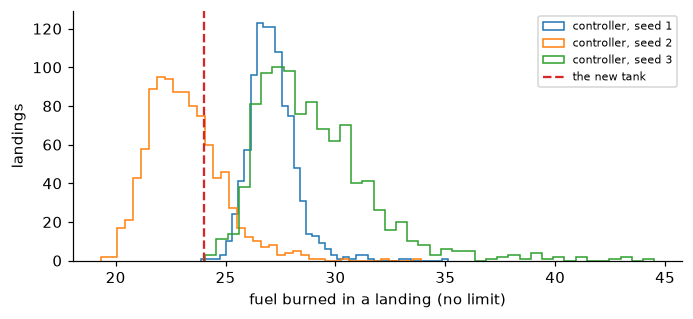

controller seed 1 under the tank: ran dry 100.0%, landed   0.0%, crashed  0.0%
controller seed 2 under the tank: ran dry  25.4%, landed  72.2%, crashed  2.4%
controller seed 3 under the tank: ran dry  99.9%, landed   0.1%, crashed  0.0%


In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for s in camp.seeds("controller"):
    ax.hist(camp.record("controller", s)["evaluation"]["fuel"], bins=40, histtype="step", label=f"controller, seed {s}")
ax.axvline(spec.budgets[0], color="C3", ls="--", label="the new tank")
ax.set_xlabel("fuel burned in a landing (no limit)"); ax.set_ylabel("landings"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
for s in camp.seeds("controller"):
    e = camp.record("controller", s)["extra_evaluations"][0]["episodes"]
    print(f"controller seed {s} under the tank: ran dry {np.mean(e['failed']):6.1%}, landed {np.mean(e['landed']):6.1%}, "
          f"crashed {np.mean(e['crashed']):5.1%}")

Training a new controller with the tank from scratch is no way out: random exploration empties the tank long before it
learns to land.

In [10]:
per_frame = np.mean([fuel_burned(None, a, None, 0.0, {})[0] for a in np.random.default_rng(0).uniform(-1, 1, (100_000, 2))])
print(f"random actions burn {per_frame:.3f} per frame: the tank is empty after about {spec.budgets[0] / per_frame:.0f} frames")

random actions burn 0.123 per frame: the tank is empty after about 195 frames


### Continue training with the tank

The training function builds the wrapped environments, starts PPO from the controller's weights, and records the
failure rate and the reward of every batch with `BudgetMonitor`. Here it runs for 300,000 frames; the campaign ran
the same function for 3 million.

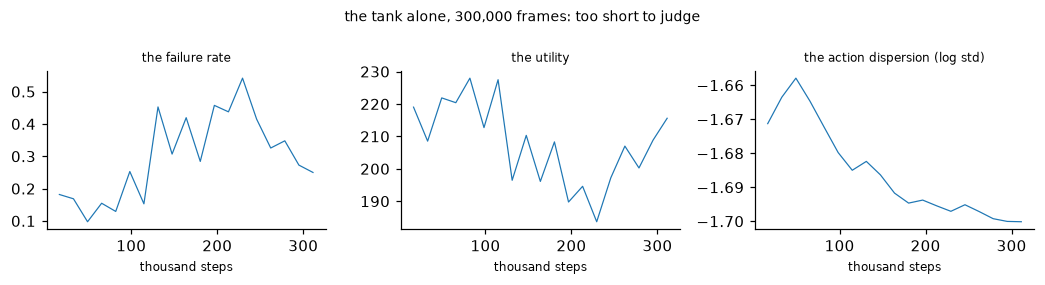

Training convergence: too short to judge (19 batches recorded; the check compares two windows of at least 10 batches). A run this short has rarely converged: train longer before comparing or deploying.
fresh landings: {'ran_dry': '30.0%', 'landed': '70.0%', 'crashed': '0.0%'}


In [11]:
def train(stage, steps, start, seed=1, anchor=None, action_anchor=None):
    model = PPO("MlpPolicy", vec_env(stage, seed), seed=seed, **PPO_SETTINGS)
    model.policy.load_state_dict(start.policy.state_dict())             # start from the controller in use
    monitor = BudgetMonitor(spec.beta, stage.m, horizon=spec.horizon)   # records every batch; checks convergence
    callbacks, regularizers = [monitor], {}
    if anchor:                                                          # weight decay toward the starting weights
        regularizers["anchor"] = ParameterAnchor(model, anchor, decoupled=False).install()   # the campaign's form, see below
    if action_anchor:                                                   # charge departures from the start's actions
        def log_start(obs, act):
            with torch.no_grad():
                return start.policy.evaluate_actions(torch.as_tensor(obs), torch.as_tensor(act))[1].numpy()
        regularizers["action anchor"] = ActionAnchor(action_anchor, log_start)
        callbacks.insert(0, regularizers["action anchor"])
    model.learn(steps, callback=callbacks)
    return model, monitor, regularizers


def landings(model, stage, n=200, seed=5):
    """Ran dry, landed and crashed, over n fresh episodes of the stochastic policy."""
    env, counts = make_env(stage), dict(ran_dry=0, landed=0, crashed=0)
    for i in range(n):
        obs, _ = env.reset(seed=seed + i)
        while True:
            obs, _, terminated, truncated, info = env.step(model.predict(obs)[0])
            if terminated or truncated:
                break
        counts["ran_dry"] += info["failure"]; counts["landed"] += info.get("landed", False); counts["crashed"] += info.get("crashed", False)
    return {k: v / n for k, v in counts.items()}


tank_alone = Stage(m=0.0, clip_utility=False)
model, monitor, _ = train(tank_alone, 300_000, controller)
monitor.plot(title="the tank alone, 300,000 frames"); plt.show()
print(monitor.convergence().explain())
print("fresh landings:", {k: f"{v:.1%}" for k, v in landings(model, tank_alone).items()})

This run is short, and the convergence check says so: the lander still runs dry about as often as the controller
did. `BudgetMonitor.convergence()` compares the last tenth of the training batches with the tenth
before; `BudgetMonitor(check_every=k, stop_when_converged=True)` checks during training and stops once the run has
converged. The campaign continued every controller for 3 million frames. Its learning curves, recorded by the same
monitor, show when the lander learns to save fuel.

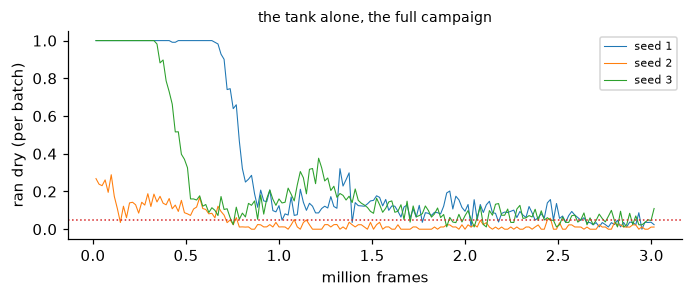

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
for r in camp.records("tank-unpriced"):
    ax.plot([t["steps"] / 1e6 for t in r["monitor"]], [t["failure_rate"] for t in r["monitor"]], lw=0.7, label=f"seed {r['seed']}")
ax.axhline(req.alpha, color="C3", ls=":", lw=1)
ax.set_xlabel("million frames"); ax.set_ylabel("ran dry (per batch)"); ax.set_title("the tank alone, the full campaign", fontsize=9)
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

Running dry ends the episode before the landing bonus, so the task's own reward already punishes it, and the wrapper
only had to make the tank part of the problem; given enough frames, the lander learns to land within it. Check the
learning curves before comparing configurations: a run stopped early tells you about its length, not about its
configuration. The campaign ran the tank alone and prices from 0.25 to 2, all for 3 million frames.

## 4. The full campaign: prices

configuration    seeds        failure (min-max)          utility (min-max)
tank-unpriced        3     3.300% (1.30%-6.00%)        241.5 (235.3-247.3)
price-0.25           3     4.667% (2.90%-7.00%)        236.9 (231.6-243.8)
price-0.5            3     6.833% (5.50%-8.10%)        223.4 (187.3-246.9)
price-1              3     5.833% (2.70%-9.30%)          212 (195.9-235.7)
price-2              3     3.933% (2.10%-7.20%)        193.4 (169.1-234.1)


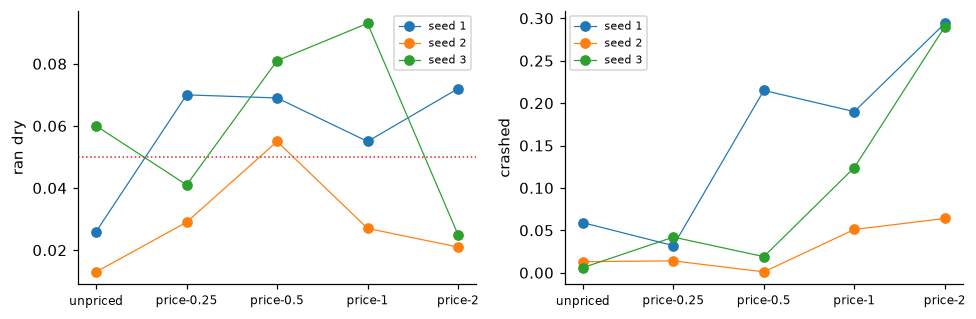

Convergence at the end of training (the toolbox's check on each run's record):
tank-unpriced        converged in 2 of 3 seeds  (still changing: seed 1: failure rate)
price-0.25           converged in 3 of 3 seeds
price-0.5            converged in 2 of 3 seeds  (still changing: seed 1: failure rate)
price-1              converged in 2 of 3 seeds  (still changing: seed 1: utility, priced objective)
price-2              converged in 2 of 3 seeds  (still changing: seed 1: utility)


In [13]:
prices = ["tank-unpriced", "price-0.25", "price-0.5", "price-1", "price-2"]
print(Campaign.show(camp.table(prices, extras=("landed", "crashed"))))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
x = np.arange(len(prices))
for k, key in enumerate(["failed", "crashed"]):
    for s in (1, 2, 3):
        vals = [np.mean(camp.record(c, s)["evaluation"][key]) if s in camp.seeds(c) else np.nan for c in prices]
        ax[k].plot(x, vals, "o-", lw=0.8, label=f"seed {s}")
    ax[k].set_xticks(x, [c.replace("tank-", "") for c in prices], fontsize=8)
    ax[k].set_ylabel({"failed": "ran dry", "crashed": "crashed"}[key]); ax[k].legend(fontsize=7)
ax[0].axhline(req.alpha, color="C3", ls=":", lw=1)
plt.tight_layout(); plt.show()
print("Convergence at the end of training (the toolbox's check on each run's record):")
print(camp.convergence_table(prices))

Most runs had converged by the end of training. Where one had not, its policy is the policy at the end of the run:
it is validated as such, and a longer run might do better.

The price adds little to the tank. Higher prices barely change how often the lander runs dry and make it crash more
often, in some seeds in a quarter of the landings or more. Once running dry costs more than a crash, the learner
sometimes chooses the crash.

**Theory.** The price charges running out, and only that. Compare it with the cost of the other ways an episode can
end badly in your task. Here continuing with the tank alone met the tolerance in two of three seeds, and no price did
better: the task's own reward already priced running dry high enough.

## 5. Regularizers that use the controller in use

The controller in use is the policy one would accept if training gained nothing, which makes it a natural reference.
The `train` function above adds either regularizer with one argument; the campaign ran both at the price 0.5:

* `anchor=kappa_p`: a **parameter anchor**, which pulls the network's weights back toward the controller's (strengths
  from 0.01 to 10);
* `action_anchor=eta`: an **action anchor**, which charges, at every frame, how far the policy's action distribution
  departs from the controller's (weight 0.05).

**Theory.** A parameter anchor biases the learned policy toward the prior policy, the policy at the anchor's weights,
and the learner inherits that policy's risk. An action anchor keeps the policy's failure risk close to the
reference's, by an amount set by how far the two action distributions are apart.

Here are the three, trained live for 300,000 frames each at the price 0.5. `ParameterAnchor.distance()` measures how
far the weights moved from the controller's, and `ActionAnchor.mean_log_ratio` how far the actions moved.

In [14]:
priced = Stage(m=0.5, clip_utility=False)
for name, options in {"no regularizer": {}, "parameter anchor, kappa_p = 1": dict(anchor=1.0),
                      "action anchor, eta = 0.05": dict(action_anchor=0.05)}.items():
    m_, mon, regs_ = train(priced, 300_000, controller, **options)
    moved = ""
    if "anchor" in regs_:
        moved = f"; weights moved {regs_['anchor'].distance():.3f}"
    if "action anchor" in regs_:
        moved = f"; mean log ratio of actions {regs_['action anchor'].mean_log_ratio:.3f}"
    outcome = landings(m_, priced)
    print(f"{name:30s} ran dry {outcome['ran_dry']:6.1%}, landed {outcome['landed']:6.1%}, crashed {outcome['crashed']:5.1%}"
          f"{moved}; training {mon.convergence().status}")

no regularizer                 ran dry  15.5%, landed  78.0%, crashed  6.5%; training too short
parameter anchor, kappa_p = 1  ran dry 100.0%, landed   0.0%, crashed  0.0%; weights moved 2.218; training too short
action anchor, eta = 0.05      ran dry  14.0%, landed  82.0%, crashed  4.0%; mean log ratio of actions 0.073; training too short


These are short runs, too short for the convergence check to judge, so the numbers show how to use the regularizers
rather than what they do after full training. Two limits of the check matter here as everywhere. A run can stop
changing in a bad place, and a learning rate that decays to zero makes any run stop changing at its end. Converged
means that the run stopped changing, not that its policy is good; the validation decides that. The full campaign
trained each for 3 million frames:

In [15]:
regs = ["price-0.5", "anchor-0.01", "anchor-0.1", "anchor-1", "anchor-10", "action-anchor"]
print(Campaign.show(camp.table(regs, extras=("landed", "crashed"))))
for cfg in ["anchor-0.01", "anchor-0.1", "anchor-1", "anchor-10"]:
    print(f"{cfg}: weight distance from the controller at the end {np.round([r['anchor_distance'] for r in camp.records(cfg)], 3)}")
print("\nConvergence at the end of training:")
print(camp.convergence_table(regs))

configuration    seeds        failure (min-max)          utility (min-max)
price-0.5            3     6.833% (5.50%-8.10%)        223.4 (187.3-246.9)
anchor-0.01          3  68.633% (19.60%-97.20%)          153 (117.3-214.9)
anchor-0.1           3  71.500% (19.20%-98.30%)        148.6 (114.7-215.7)
anchor-1             3   69.300% (8.80%-99.90%)        138.6 (108.5-194.3)
anchor-10            3  89.200% (72.70%-99.80%)          127 (108.3-152.8)
action-anchor        3     4.867% (1.40%-8.70%)        226.3 (212.5-245.2)
anchor-0.01: weight distance from the controller at the end [0.037 0.01  0.033]
anchor-0.1: weight distance from the controller at the end [0.102 0.113 0.082]
anchor-1: weight distance from the controller at the end [0.201 0.265 0.196]
anchor-10: weight distance from the controller at the end [0.267 0.288 0.268]

Convergence at the end of training:
price-0.5            converged in 2 of 3 seeds  (still changing: seed 1: failure rate)
anchor-0.01          converged in 3 o

The parameter anchor keeps the controller's flaw. The controller runs dry under the new tank, and anchored to its
weights the lander keeps running dry, at every strength tried, down to 0.01. The prior policy here is one the new
requirement rejects, and the learner inherits its risk.

These runs, and the short ones above, use the coupled form of the anchor (`decoupled=False`): the pull is added to
the policy gradient before Adam's step, the form of the paper's runs. Adam divides every gradient coordinate by its
running root-mean-square, so the pull's step is about the learning rate whatever the distance to the anchor and
whatever the strength, and the strength does not read as a curvature. The toolbox's default is the decoupled form,
`theta <- theta - lr kappa_p (theta - theta_0)` applied to the weights after the step, under which every weight
contracts toward the anchor by `1 - lr kappa_p` per step and the strength keeps its meaning (the paper's guidance;
`ParameterAnchor`'s docstring). Whether the anchored lander still runs dry under the decoupled form at these
strengths is not tested here.

The action anchor holds the behavior near the controller and gives way where the tank demands a change. With it the
lander learned to save fuel as well as without it; its effect on crashes was mixed across seeds.

When the policy in use violates the new limit: start from it, and if you regularize toward it, regularize its
behavior, not its weights.

## 6. Validate the policy to deploy, and report

Ten candidates were inspected, so the validation error is shared among ten. We take the candidate with the highest
landing rate among those that met the tolerance on their first evaluation, and validate it on 2,000 fresh landings,
as a stochastic policy and as its mean action, which are different candidates.

**Theory.** The exact binomial test holds for any fixed policy, however it was trained; it is the deployment
decision. Certificates from the value need no validation run, but over 1000 frames they are valid and uninformative.

In [16]:
cands = [(c, s) for c in prices + regs[1:] for s in camp.seeds(c)]
ok = [cs for cs in cands if np.mean(camp.record(*cs)["evaluation"]["failed"]) < req.alpha]
best = max(ok, key=lambda cs: np.mean(camp.record(*cs)["evaluation"]["landed"]))
print("candidate:", best, camp.record(*best)["note"])
best_stage = camp.stage(*best)
for det in (False, True):
    e = evaluate(lambda: make_env(best_stage), camp.policy(*best, deterministic=det), 2000, spec=spec, stage=best_stage,
                 T=req.T, seed=777)
    name = f"the {'mean action of the' if det else 'stochastic'} policy {best[0]}, seed {best[1]}"
    print()
    print(interpret(spec, req, best_stage, e, candidate_name=name, training=camp.convergence(*best)).summary(resource="fuel", period="frames"))

candidate: ('tank-unpriced', 2) the tank imposed, no price

The stochastic policy tank-unpriced, seed 2 was run on 2000 fresh episodes. It ran out of fuel within 1000 frames in 25 of them (1.25%).
With confidence 0.95, its probability of running out within 1000 frames is at most 2.042% (the error 0.05 is shared among 10 candidates).
Requirement (at most 5.00%): met.
Utility per episode: 246.8 (standard error 0.73).
Episodes that came within 5% of running out, or ran out: 5.8%.
Training had converged by the toolbox's check (the last 18 batches against the 18 before).

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 1000 frames, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().

The mean action of the policy tank-unpriced, seed 2 was run on 2000 fresh episodes. 

The candidate that learned the tank without a price passes, as a stochastic policy and as its mean action. On this
task, imposing the tank and continuing to train did the work and the price had nothing to add; the validation is
what shows that the policy meets the requirement.

## Your own task

To add a budget to a task you already train, change these cells:

1. `fuel_burned`: the resource one step consumes (nonnegative; for a resource that is also replenished, wrap the
   signed use in `barrierpg.RunningMaxCost`);
2. `spec` and `req`: the budget, the horizon, the discount, bounds on the reward, and the requirement;
3. `stage`: the price, or a lump sum if failure has a known cost (`Stage(penalty="multiplier", multiplier=F)`);
4. `make_env`: your Gymnasium task inside `BudgetWrapper` (add `observe_time=True` if the horizon is fixed and the
   task does not observe the time);
5. `PPO_SETTINGS` and `train`: your learner's settings, with `gamma = spec.beta`.

Then check the wrapped environment, plan, train at a few prices, and validate the policy you deploy. The campaign's
configurations are in `campaigns/problems.py`; `python campaigns/run.py lander price-0.5 --seed 4` reruns one.